# Matrix transformations: move pixels with a 2×2 matrix

A matrix can transform every point in an image at once. In this lesson, you will connect matrix columns to transformed basis vectors, then apply scaling, rotation, and shearing to a real image.

**By the end, you should be able to** read a 2D transformation from its matrix, combine transformations by multiplication, and explain why image resampling uses the inverse matrix.

## 1. A matrix transforms points

We represent a point as a column vector `p = [x, y]`. Multiplying by a matrix `A` gives the transformed point `A * p`. The first column of `A` is where the horizontal basis vector `[1, 0]` goes; the second column is where the vertical basis vector `[0, 1]` goes.

In the image coordinates used later, `x` increases to the right and `y` increases down the screen. The origin for the examples will be the center of the image, so these transformations keep that center fixed.

In [1]:
using LinearAlgebra
using Images
using ImageIO

e₁ = [1.0, 0.0]
e₂ = [0.0, 1.0]

A = [1.5 0.0;
     0.0 0.75]
(A * e₁, A * e₂)

([1.5, 0.0], [0.0, 0.75])

The columns of `A` are the two transformed basis vectors. Here, horizontal distances are multiplied by 1.5 and vertical distances by 0.75. Try changing the entries and predict where each basis vector will land.

## 2. Load an image

An image is a two-dimensional array of pixels. We will use the first two dimensions as rows and columns. For this notebook, a point `[x, y]` means `[column, row]`.

In [2]:
image_path = joinpath(@__DIR__, "..", "images", "great-wave-kanagawa.png")
img = load(image_path)
size(img)

(670, 1280)

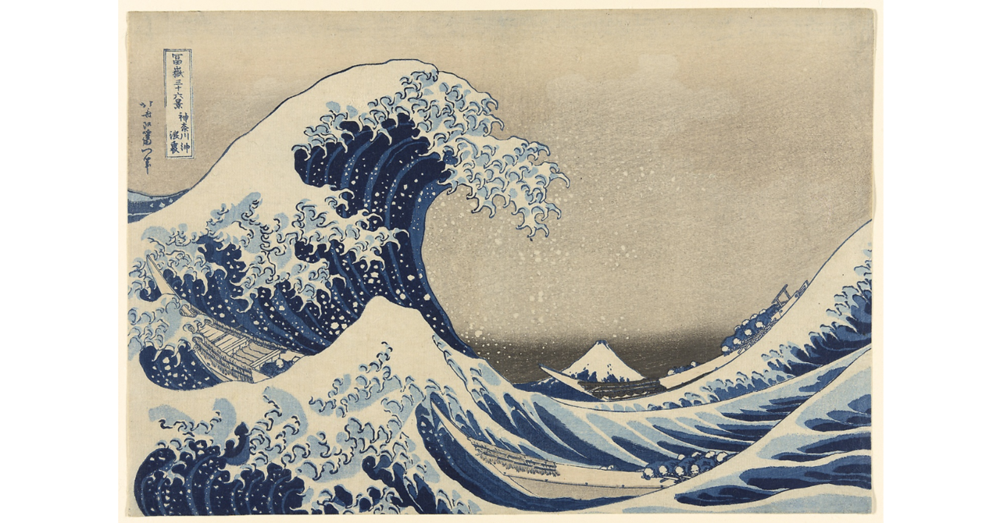

In [3]:
img

## 3. Turn a matrix into a transformed image

A forward map sends each source pixel to a new location. On a discrete pixel grid, some destination pixels can be skipped, leaving holes. Instead, we visit every destination pixel and ask where it came from. That means mapping destination coordinates back with `inv(A)` and sampling the nearest source pixel.

This simple renderer keeps the original canvas size. Pixels that map outside the source image are filled with black; nearest-neighbor sampling can look blocky. Those are rendering choices, separate from the matrix algebra.

In [4]:
function transform_image(image, A)
    height, width = size(image)
    output = fill(zero(eltype(image)), size(image))
    center_x = (width + 1) / 2
    center_y = (height + 1) / 2
    A_inv = inv(A)

    for row in 1:height, col in 1:width
        x_out = col - center_x
        y_out = row - center_y
        x_in = A_inv[1, 1] * x_out + A_inv[1, 2] * y_out
        y_in = A_inv[2, 1] * x_out + A_inv[2, 2] * y_out
        source_col = round(Int, x_in + center_x)
        source_row = round(Int, y_in + center_y)

        if 1 <= source_row <= height && 1 <= source_col <= width
            output[row, col] = image[source_row, source_col]
        end
    end

    output
end

transform_image (generic function with 1 method)

## 4. Scaling

A diagonal matrix scales each coordinate independently. A scale factor below 1 makes the subject smaller; a factor above 1 makes it larger. The image remains centered, and the canvas dimensions do not change.

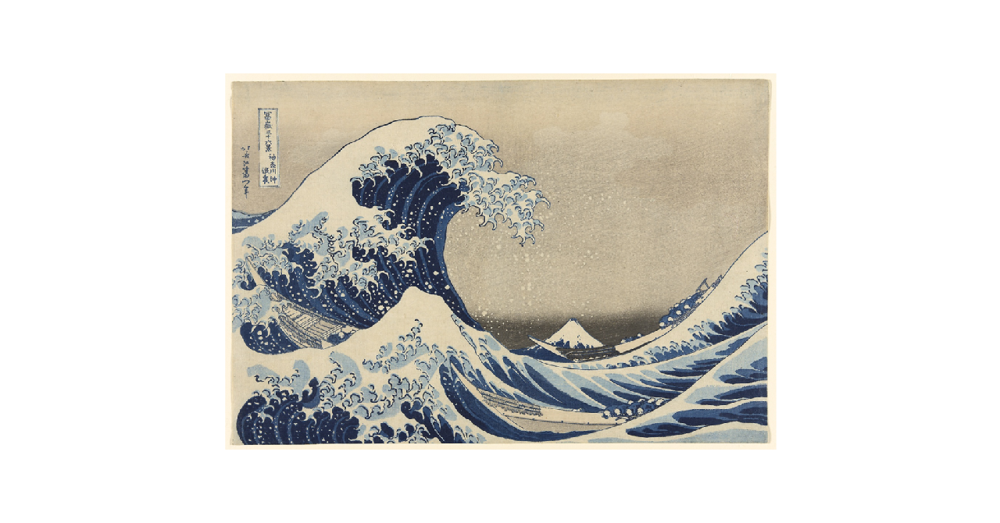

In [5]:
scale = [0.72 0.0;
         0.0 0.72]
scaled_img = transform_image(img, scale)
scaled_img

**Think about it:** What happens if you use `[1.25 0; 0 1.25]` instead? Why might part of the image disappear?

## 5. Rotation

The familiar rotation matrix is built from sine and cosine. Since image `y` coordinates increase downward, a positive angle appears clockwise on screen.

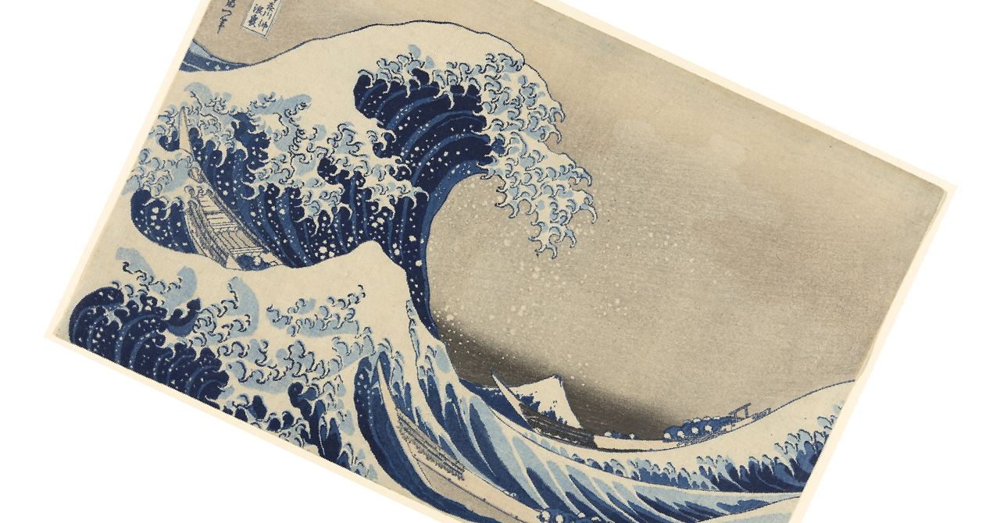

In [6]:
θ = deg2rad(25)
rotation = [cos(θ) -sin(θ);
            sin(θ)  cos(θ)]
rotated_img = transform_image(img, rotation)
rotated_img

The output still has the original width and height, so rotated corners may be clipped. The matrix rotates points around the image center because the renderer recenters coordinates before applying it.

## 6. Shearing

A shear slants the image. In this matrix, the horizontal position changes with vertical position, while the vertical coordinate stays fixed.

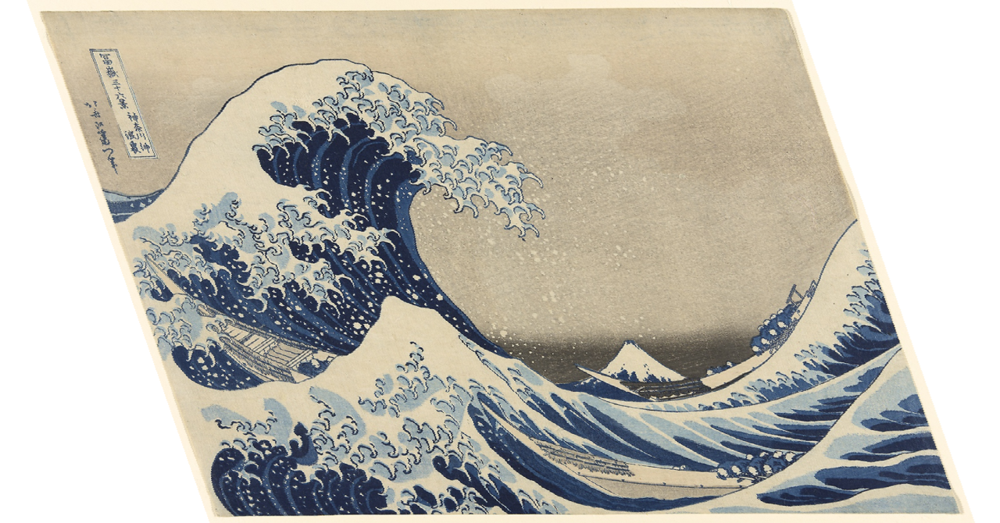

In [7]:
shear = [1.0 0.35;
         0.0 1.0]
sheared_img = transform_image(img, shear)
sheared_img

## 7. Compose transformations

Matrix multiplication combines transformations. With column vectors, the rightmost matrix acts first. So `rotation * shear` shears a point and then rotates it; in general, reversing the order gives a different result.

In [8]:
combined = rotation * shear
(rotation * (shear * e₁), combined * e₁)

([0.9063077870366499, 0.42261826174069944], [0.9063077870366499, 0.42261826174069944])

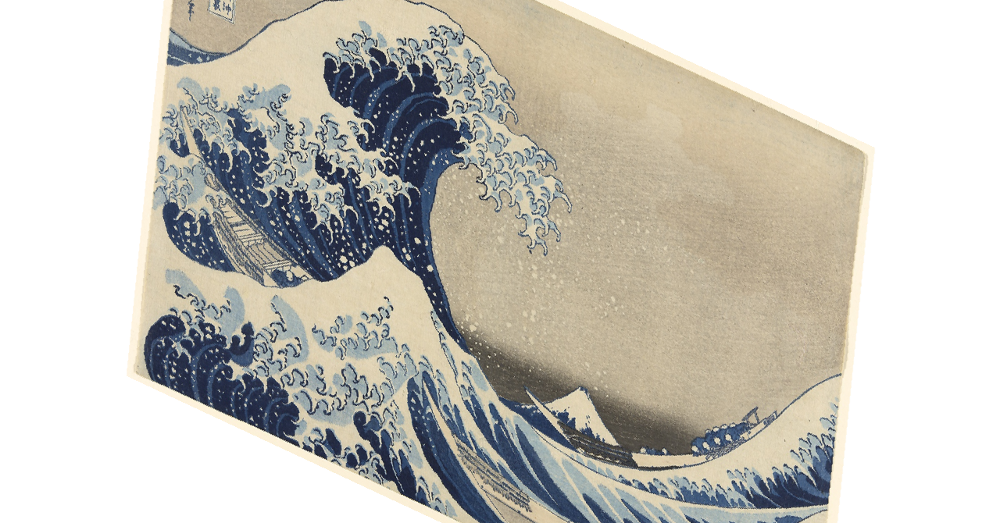

In [9]:
combined_img = transform_image(img, combined)
combined_img

## Your turn

1. Make a matrix that reflects the image left-to-right. What happens to the determinant?
2. Try `rotation * shear` and `shear * rotation` on the image. Compare the results. Why are they different?
3. Change the scale factors independently. Which matrix changes the image's aspect ratio?

For an invertible 2×2 matrix, the determinant gives the area scale factor in magnitude. A negative determinant also reverses orientation. The renderer here requires an invertible matrix because it maps output pixels back using `inv(A)`.